In [1]:
import sys
print(sys.executable)

c:\Users\Rachitesh Sharma\Documents\Business-Decision-Intelligence\.venv\Scripts\python.exe


In [2]:
import pandas as pd


In [3]:
import pandas as pd

# Load Orders
orders = pd.read_csv("../01_data/raw/olist_orders_dataset.csv")

# Basic inspection
print("=" * 70)
print("ORDERS DATASET")
print("=" * 70)

print("\nSHAPE")
print(orders.shape)

print("\nCOLUMNS")
print(orders.columns)

print("\nDATA TYPES")
print(orders.dtypes)

print("\nMISSING VALUES")
print(orders.isnull().sum())

print("\nDUPLICATE ROWS")
print(orders.duplicated().sum())

print("\nORDER STATUS")
print(orders["order_status"].value_counts())

ORDERS DATASET

SHAPE
(99441, 8)

COLUMNS
Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='str')

DATA TYPES
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

MISSING VALUES
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

DUPLICATE ROWS
0

ORDER STATUS
order_status
delivered      96478
shippe

In [4]:
from pathlib import Path

raw_folder = Path("../01_data/raw")

files = {
    "customers": "olist_customers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "category_translation": "product_category_name_translation.csv"
}

data = {}

for name, filename in files.items():
    data[name] = pd.read_csv(raw_folder / filename)

print(f"Loaded {len(data)} datasets successfully.")

Loaded 9 datasets successfully.


In [5]:
import pandas as pd
from pathlib import Path

raw_folder = Path("../01_data/raw")

files = {
    "customers": "olist_customers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "category_translation": "product_category_name_translation.csv"
}

data = {}

for name, filename in files.items():

    df = pd.read_csv(raw_folder / filename)
    data[name] = df

    print("\n" + "=" * 70)
    print(name.upper())
    print("=" * 70)

    print("\nSHAPE")
    print(df.shape)

    print("\nCOLUMNS")
    print(list(df.columns))

    print("\nDATA TYPES")
    print(df.dtypes)

    print("\nMISSING VALUES")
    print(df.isnull().sum())

    print("\nDUPLICATE ROWS")
    print(df.duplicated().sum())

print("\n" + "=" * 70)
print(f"TOTAL DATASETS LOADED: {len(data)}")
print("=" * 70)


CUSTOMERS

SHAPE
(99441, 5)

COLUMNS
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

DATA TYPES
customer_id                   str
customer_unique_id            str
customer_zip_code_prefix    int64
customer_city                 str
customer_state                str
dtype: object

MISSING VALUES
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

DUPLICATE ROWS
0

GEOLOCATION

SHAPE
(1000163, 5)

COLUMNS
['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']

DATA TYPES
geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                   str
geolocation_state                  str
dtype: object

MISSING VALUES
geolocation_zip_code_prefix    0
geolocation_lat                0
geolocation_

In [6]:
orders = data["orders"].copy()

In [7]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"]

for column in date_columns:
    orders[column] = pd.to_datetime(orders[column])

print(orders[date_columns].dtypes)


order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object


In [8]:
orders.groupby("order_status")[
    [
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date"
    ]
].apply(lambda x: x.isnull().sum())


,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
order_status,,,
approved,0,2,2
canceled,141,550,619
created,5,5,5
delivered,14,2,8
invoiced,0,314,314
processing,0,301,301
shipped,0,0,1107
unavailable,0,609,609


In [9]:
orders[
    (orders['order_status'] == 'delivered')&
    (orders['order_approved_at'].isnull())
]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
5323,e04abd8149ef81b95221e88f6ed9ab6a,2127dc6603ac33544953ef05ec155771,delivered,2017-02-18 14:40:00,NaT,2017-02-23 12:04:47,2017-03-01 13:25:33,2017-03-17
16567,8a9adc69528e1001fc68dd0aaebbb54a,4c1ccc74e00993733742a3c786dc3c1f,delivered,2017-02-18 12:45:31,NaT,2017-02-23 09:01:52,2017-03-02 10:05:06,2017-03-21
19031,7013bcfc1c97fe719a7b5e05e61c12db,2941af76d38100e0f8740a374f1a5dc3,delivered,2017-02-18 13:29:47,NaT,2017-02-22 16:25:25,2017-03-01 08:07:38,2017-03-17
22663,5cf925b116421afa85ee25e99b4c34fb,29c35fc91fc13fb5073c8f30505d860d,delivered,2017-02-18 16:48:35,NaT,2017-02-22 11:23:10,2017-03-09 07:28:47,2017-03-31
23156,12a95a3c06dbaec84bcfb0e2da5d228a,1e101e0daffaddce8159d25a8e53f2b2,delivered,2017-02-17 13:05:55,NaT,2017-02-22 11:23:11,2017-03-02 11:09:19,2017-03-20
26800,c1d4211b3dae76144deccd6c74144a88,684cb238dc5b5d6366244e0e0776b450,delivered,2017-01-19 12:48:08,NaT,2017-01-25 14:56:50,2017-01-30 18:16:01,2017-03-01
38290,d69e5d356402adc8cf17e08b5033acfb,68d081753ad4fe22fc4d410a9eb1ca01,delivered,2017-02-19 01:28:47,NaT,2017-02-23 03:11:48,2017-03-02 03:41:58,2017-03-27
39334,d77031d6a3c8a52f019764e68f211c69,0bf35cac6cc7327065da879e2d90fae8,delivered,2017-02-18 11:04:19,NaT,2017-02-23 07:23:36,2017-03-02 16:15:23,2017-03-22
48401,7002a78c79c519ac54022d4f8a65e6e8,d5de688c321096d15508faae67a27051,delivered,2017-01-19 22:26:59,NaT,2017-01-27 11:08:05,2017-02-06 14:22:19,2017-03-16
61743,2eecb0d85f281280f79fa00f9cec1a95,a3d3c38e58b9d2dfb9207cab690b6310,delivered,2017-02-17 17:21:55,NaT,2017-02-22 11:42:51,2017-03-03 12:16:03,2017-03-20


In [10]:
orders[
    (orders['order_status'] == 'delivered')&
    (orders['order_delivered_customer_date'].isnull())
]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaT,2017-12-18
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaT,2018-07-16
43834,2ebdfc4f15f23b91474edf87475f108e,29f0540231702fda0cfdee0a310f11aa,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaT,2018-07-30
79263,e69f75a717d64fc5ecdfae42b2e8e086,cfda40ca8dd0a5d486a9635b611b398a,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaT,2018-07-30
82868,0d3268bad9b086af767785e3f0fc0133,4f1d63d35fb7c8999853b2699f5c7649,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaT,2018-07-24
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaT,NaT,2017-06-23
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,dd1b84a7286eb4524d52af4256c0ba24,delivered,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaT,2018-06-26
98038,20edc82cf5400ce95e1afacc25798b31,28c37425f1127d887d7337f284080a0f,delivered,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaT,2018-07-19


In [11]:
orders["delivery_days"] = (
    orders["order_delivered_customer_date"] -
    orders["order_purchase_timestamp"]
).dt.total_seconds() / (60 * 60 * 24)



In [12]:
orders[["order_status", "order_purchase_timestamp", "order_delivered_customer_date", "delivery_days"]].head()

,order_status,order_purchase_timestamp,order_delivered_customer_date,delivery_days
0,delivered,2017-10-02 10:56:33,2017-10-10 21:25:13,8.436574
1,delivered,2018-07-24 20:41:37,2018-08-07 15:27:45,13.782037
2,delivered,2018-08-08 08:38:49,2018-08-17 18:06:29,9.394213
3,delivered,2017-11-18 19:28:06,2017-12-02 00:28:42,13.208750
4,delivered,2018-02-13 21:18:39,2018-02-16 18:17:02,2.873877


In [13]:
orders["delivery_days"].describe()

count    96476.000000
mean        12.558702
std          9.546530
min          0.533414
25%          6.766403
50%         10.217755
75%         15.720327
max        209.628611
Name: delivery_days, dtype: float64

In [14]:
orders.sort_values("delivery_days", ascending=False).head(10)[
   
    ['order_id',
    'order_status',
    'order_purchase_timestamp',
    'order_delivered_customer_date',
    'delivery_days'
    ]
]

,order_id,order_status,order_purchase_timestamp,order_delivered_customer_date,delivery_days
19590,ca07593549f1816d26a572e06dc1eab6,delivered,2017-02-21 23:31:27,2017-09-19 14:36:39,209.628611
55619,1b3190b2dfa9d789e1f14c05b647a14a,delivered,2018-02-23 14:57:35,2018-09-19 23:24:07,208.351759
61610,440d0d17af552815d15a9e41abe49359,delivered,2017-03-07 23:59:51,2017-09-19 15:12:50,195.634016
70307,2fb597c2f772eca01b1f5c561bf6cc7b,delivered,2017-03-08 18:09:02,2017-09-19 14:33:17,194.850174
89130,285ab9426d6982034523a855f55a885e,delivered,2017-03-08 22:47:40,2017-09-19 14:00:04,194.633611
38509,0f4519c5f1c541ddec9f21b3bddd533a,delivered,2017-03-09 13:26:57,2017-09-19 14:38:21,194.049583
11399,47b40429ed8cce3aee9199792275433f,delivered,2018-01-03 09:44:01,2018-07-13 20:51:31,191.463542
81401,2fe324febf907e3ea3f2aa9650869fa5,delivered,2017-03-13 20:17:10,2017-09-19 17:00:07,189.863160
54480,2d7561026d542c8dbd8f0daeadf67a43,delivered,2017-03-15 11:24:27,2017-09-19 14:38:18,188.134618
68769,c27815f7e3dd0b926b58552628481575,delivered,2017-03-15 23:23:17,2017-09-19 17:14:25,187.743843


In [15]:
orders.sort_values('delivery_days', ascending=False).head(10)[
    ['order_id',
     'order_status',
     'order_purchase_timestamp',
     'order_approved_at',
     'order_delivered_carrier_date',
     'order_delivered_customer_date',
     'order_estimated_delivery_date',
     'delivery_days']
]

,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days
19590,ca07593549f1816d26a572e06dc1eab6,delivered,2017-02-21 23:31:27,2017-02-23 02:35:15,2017-03-08 13:47:46,2017-09-19 14:36:39,2017-03-22,209.628611
55619,1b3190b2dfa9d789e1f14c05b647a14a,delivered,2018-02-23 14:57:35,2018-02-23 15:16:14,2018-02-26 18:49:07,2018-09-19 23:24:07,2018-03-15,208.351759
61610,440d0d17af552815d15a9e41abe49359,delivered,2017-03-07 23:59:51,2017-03-09 01:11:33,2017-03-15 13:00:08,2017-09-19 15:12:50,2017-04-07,195.634016
70307,2fb597c2f772eca01b1f5c561bf6cc7b,delivered,2017-03-08 18:09:02,2017-03-08 18:09:02,2017-03-13 08:54:02,2017-09-19 14:33:17,2017-04-17,194.850174
89130,285ab9426d6982034523a855f55a885e,delivered,2017-03-08 22:47:40,2017-03-08 22:47:40,2017-03-09 08:53:20,2017-09-19 14:00:04,2017-04-06,194.633611
38509,0f4519c5f1c541ddec9f21b3bddd533a,delivered,2017-03-09 13:26:57,2017-03-09 13:26:57,2017-03-22 05:28:14,2017-09-19 14:38:21,2017-04-11,194.049583
11399,47b40429ed8cce3aee9199792275433f,delivered,2018-01-03 09:44:01,2018-01-03 10:31:15,2018-02-06 01:48:28,2018-07-13 20:51:31,2018-01-19,191.463542
81401,2fe324febf907e3ea3f2aa9650869fa5,delivered,2017-03-13 20:17:10,2017-03-13 20:17:10,2017-03-17 07:23:53,2017-09-19 17:00:07,2017-04-05,189.863160
54480,2d7561026d542c8dbd8f0daeadf67a43,delivered,2017-03-15 11:24:27,2017-03-15 11:24:27,2017-03-16 09:29:16,2017-09-19 14:38:18,2017-04-13,188.134618
68769,c27815f7e3dd0b926b58552628481575,delivered,2017-03-15 23:23:17,2017-03-15 23:23:17,2017-03-21 14:50:25,2017-09-19 17:14:25,2017-04-10,187.743843


In [16]:
data["order_items"][data["order_items"]["order_id"] == "ca07593549f1816d26a572e06dc1eab6"]

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
88935,ca07593549f1816d26a572e06dc1eab6,1,8eed5d27f5b8c6248731efb4782f6141,2a1348e9addc1af5aaa619b1a3679d6b,2017-02-25 23:31:27,229.9,15.78


In [17]:
data['payments'][data['payments']['order_id'] == "ca07593549f1816d26a572e06dc1eab6"]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
85133,ca07593549f1816d26a572e06dc1eab6,1,boleto,1,245.68


In [18]:
orders[orders["order_id"] == "ca07593549f1816d26a572e06dc1eab6"][[
    "order_id","customer_id"
]]
               

,order_id,customer_id
19590,ca07593549f1816d26a572e06dc1eab6,75683a92331068e2d281b11a7866ba44


In [19]:
data["customers"][data["customers"]["customer_id"] == "75683a92331068e2d281b11a7866ba44"][[
    "customer_id",
    "customer_unique_id",
    "customer_city",
    "customer_state"
]]

,customer_id,customer_unique_id,customer_city,customer_state
27777,75683a92331068e2d281b11a7866ba44,4a2519b6991378f6f2ce5ed22d308f03,montanha,ES


In [20]:
data["reviews"][data["reviews"]["order_id"] == "ca07593549f1816d26a572e06dc1eab6"][[
    "order_id",
    "review_score",
    "review_creation_date",
    "review_answer_timestamp"
]]

,order_id,review_score,review_creation_date,review_answer_timestamp


In [21]:
data["orders"][data["orders"]["order_delivered_customer_date"] == pd.Timestamp("2017-09-19").date()].shape[0]

0

In [22]:
orders["order_delivered_customer_date"].dt.date.value_counts().head(10)

order_delivered_customer_date
2018-08-27    446
2018-08-13    442
2018-05-14    434
2018-05-21    431
2018-05-18    425
2018-04-11    413
2017-12-11    412
2018-07-03    410
2018-05-03    409
2018-07-30    405
Name: count, dtype: int64

In [23]:
orders["order_delivered_customer_date"].dt.date.eq(pd.Timestamp("2017-09-19").date()).sum()

np.int64(282)

In [24]:
orders[orders["order_delivered_customer_date"].dt.date == pd.Timestamp("2017-09-19").date()].shape[0]

282

In [25]:
orders[
    orders["order_delivered_customer_date"].dt.date == pd.Timestamp("2017-09-19").date()
]["order_purchase_timestamp"].min()

Timestamp('2017-02-21 23:31:27')

In [26]:
orders[
    orders["order_delivered_customer_date"].dt.date == pd.Timestamp("2017-09-19").date()
]["order_purchase_timestamp"].max()

Timestamp('2017-09-18 15:07:49')

In [27]:
orders["order_delivered_customer_date"].dt.date.eq(
    pd.Timestamp("2018-09-19").date()
).sum()

np.int64(3)

In [28]:
orders[
    orders["order_delivered_customer_date"].dt.date == pd.Timestamp("2017-09-19").date()
].groupby(
    orders["order_purchase_timestamp"].dt.to_period("M")
).size()

order_purchase_timestamp
2017-02      1
2017-03     11
2017-04      7
2017-05      2
2017-06      3
2017-07      7
2017-08     47
2017-09    204
Freq: M, dtype: int64

In [29]:
orders[
    (orders["order_delivered_customer_date"].dt.date == pd.Timestamp("2017-09-19").date()) &
    (orders["order_purchase_timestamp"] < pd.Timestamp("2017-08-01"))
].shape[0]

31

In [30]:
orders[
    (orders["order_delivered_customer_date"].dt.date == pd.Timestamp("2017-09-19").date()) &
    (orders["order_purchase_timestamp"] < pd.Timestamp("2017-08-01"))
].shape[0]

31

In [31]:
orders[
    (orders["order_delivered_customer_date"].dt.date == pd.Timestamp("2017-09-19").date()) &
    (orders["order_purchase_timestamp"] < pd.Timestamp("2017-08-01"))
]["delivery_days"].min()

np.float64(55.25734953703704)

In [32]:
orders[
    (orders["order_delivered_customer_date"].dt.date == pd.Timestamp("2017-09-19").date()) &
    (orders["order_purchase_timestamp"] < pd.Timestamp("2017-08-01"))
]["delivery_days"].max()

np.float64(209.6286111111111)

In [33]:
orders[
    (orders["order_delivered_customer_date"].dt.date == pd.Timestamp("2017-09-19").date()) &
    (orders["order_purchase_timestamp"] < pd.Timestamp("2017-08-01"))
]["delivery_days"].median()

np.float64(166.1417361111111)

In [34]:
import pandas as pd
import numpy as np
from pathlib import Path


# ============================================================
# 1. LOAD RAW DATA
# ============================================================

raw_folder = Path("../01_data/raw")

files = {
    "customers": "olist_customers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "category_translation": "product_category_name_translation.csv"
}

cleaned_data = {}

for name, filename in files.items():
    cleaned_data[name] = pd.read_csv(raw_folder / filename)


# ============================================================
# 2. GENERAL TEXT CLEANING
# ============================================================

for name, df in cleaned_data.items():

    text_columns = df.select_dtypes(include=["object"]).columns

    for column in text_columns:
        df[column] = df[column].str.strip()

    cleaned_data[name] = df


# ============================================================
# 3. CUSTOMERS CLEANING
# ============================================================

customers = cleaned_data["customers"].copy()

customers["customer_zip_code_prefix"] = (
    customers["customer_zip_code_prefix"]
    .astype("Int64")
    .astype("string")
)

customers["customer_state"] = customers["customer_state"].str.upper()

customers = customers.drop_duplicates()

cleaned_data["customers"] = customers


# ============================================================
# 4. GEOLOCATION CLEANING
# ============================================================

geolocation = cleaned_data["geolocation"].copy()

geolocation["geolocation_zip_code_prefix"] = (
    geolocation["geolocation_zip_code_prefix"]
    .astype("Int64")
    .astype("string")
)

geolocation["geolocation_lat"] = pd.to_numeric(
    geolocation["geolocation_lat"],
    errors="coerce"
)

geolocation["geolocation_lng"] = pd.to_numeric(
    geolocation["geolocation_lng"],
    errors="coerce"
)

geolocation["geolocation_state"] = (
    geolocation["geolocation_state"]
    .str.upper()
)

# Remove only exact duplicate rows.
# Multiple coordinates for the same ZIP are preserved.
geolocation = geolocation.drop_duplicates()

cleaned_data["geolocation"] = geolocation


# ============================================================
# 5. ORDER ITEMS CLEANING
# ============================================================

order_items = cleaned_data["order_items"].copy()

order_items["shipping_limit_date"] = pd.to_datetime(
    order_items["shipping_limit_date"],
    errors="coerce"
)

order_items["price"] = pd.to_numeric(
    order_items["price"],
    errors="coerce"
)

order_items["freight_value"] = pd.to_numeric(
    order_items["freight_value"],
    errors="coerce"
)

order_items["order_item_id"] = pd.to_numeric(
    order_items["order_item_id"],
    errors="coerce"
).astype("Int64")

order_items = order_items.drop_duplicates()

cleaned_data["order_items"] = order_items


# ============================================================
# 6. PAYMENTS CLEANING
# ============================================================

payments = cleaned_data["payments"].copy()

payments["payment_sequential"] = pd.to_numeric(
    payments["payment_sequential"],
    errors="coerce"
).astype("Int64")

payments["payment_installments"] = pd.to_numeric(
    payments["payment_installments"],
    errors="coerce"
).astype("Int64")

payments["payment_value"] = pd.to_numeric(
    payments["payment_value"],
    errors="coerce"
)

payments["payment_type"] = payments["payment_type"].str.lower()

payments = payments.drop_duplicates()

cleaned_data["payments"] = payments


# ============================================================
# 7. REVIEWS CLEANING
# ============================================================

reviews = cleaned_data["reviews"].copy()

reviews["review_score"] = pd.to_numeric(
    reviews["review_score"],
    errors="coerce"
).astype("Int64")

reviews["review_creation_date"] = pd.to_datetime(
    reviews["review_creation_date"],
    errors="coerce"
)

reviews["review_answer_timestamp"] = pd.to_datetime(
    reviews["review_answer_timestamp"],
    errors="coerce"
)

reviews["review_comment_title"] = (
    reviews["review_comment_title"]
    .str.strip()
)

reviews["review_comment_message"] = (
    reviews["review_comment_message"]
    .str.strip()
)

reviews = reviews.drop_duplicates()

cleaned_data["reviews"] = reviews


# ============================================================
# 8. ORDERS CLEANING
# ============================================================

orders = cleaned_data["orders"].copy()

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    orders[column] = pd.to_datetime(
        orders[column],
        errors="coerce"
    )

orders["order_status"] = (
    orders["order_status"]
    .str.strip()
    .str.lower()
)

orders = orders.drop_duplicates()


# ============================================================
# 9. ORDER-LEVEL DERIVED FIELDS
# ============================================================

# Whether the order has actually been delivered
orders["is_delivered"] = (
    orders["order_status"] == "delivered"
)


# Actual delivery time in days
orders["delivery_days"] = (
    orders["order_delivered_customer_date"]
    - orders["order_purchase_timestamp"]
).dt.total_seconds() / (60 * 60 * 24)


# Estimated delivery delay
# Positive = delivered after estimated date
# Negative = delivered before estimated date
orders["delivery_delay_days"] = (
    orders["order_delivered_customer_date"].dt.normalize()
    - orders["order_estimated_delivery_date"].dt.normalize()
).dt.days


# Delivery performance category
orders["delivery_performance"] = np.select(
    [
        orders["delivery_delay_days"].isna(),
        orders["delivery_delay_days"] <= 0,
        orders["delivery_delay_days"] > 0
    ],
    [
        "Unknown",
        "On Time / Early",
        "Late"
    ],
    default="Unknown"
)


cleaned_data["orders"] = orders


# ============================================================
# 10. PRODUCTS CLEANING
# ============================================================

products = cleaned_data["products"].copy()

numeric_product_columns = [
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

for column in numeric_product_columns:
    products[column] = pd.to_numeric(
        products[column],
        errors="coerce"
    )

products["product_category_name"] = (
    products["product_category_name"]
    .str.strip()
)

products = products.drop_duplicates()

cleaned_data["products"] = products


# ============================================================
# 11. SELLERS CLEANING
# ============================================================

sellers = cleaned_data["sellers"].copy()

sellers["seller_zip_code_prefix"] = (
    sellers["seller_zip_code_prefix"]
    .astype("Int64")
    .astype("string")
)

sellers["seller_state"] = sellers["seller_state"].str.upper()

sellers = sellers.drop_duplicates()

cleaned_data["sellers"] = sellers


# ============================================================
# 12. CATEGORY TRANSLATION CLEANING
# ============================================================

category_translation = cleaned_data[
    "category_translation"
].copy()

category_translation[
    "product_category_name"
] = (
    category_translation["product_category_name"]
    .str.strip()
)

category_translation[
    "product_category_name_english"
] = (
    category_translation["product_category_name_english"]
    .str.strip()
)

category_translation = category_translation.drop_duplicates()

cleaned_data["category_translation"] = category_translation


# ============================================================
# 13. BASIC DATA VALIDATION
# ============================================================

print("=" * 70)
print("CLEANING COMPLETED")
print("=" * 70)

for name, df in cleaned_data.items():

    print(
        f"{name:20} "
        f"rows={len(df):>8,} | "
        f"columns={len(df.columns):>2} | "
        f"missing={df.isna().sum().sum():>8,} | "
        f"duplicates={df.duplicated().sum():>6,}"
    )


# ============================================================
# 14. KEY RELATIONSHIP VALIDATION
# ============================================================

print("\n" + "=" * 70)
print("RELATIONSHIP VALIDATION")
print("=" * 70)


checks = {

    "order_items -> orders":
        (~order_items["order_id"].isin(
            orders["order_id"]
        )).sum(),

    "orders -> customers":
        (~orders["customer_id"].isin(
            customers["customer_id"]
        )).sum(),

    "order_items -> products":
        (~order_items["product_id"].isin(
            products["product_id"]
        )).sum(),

    "order_items -> sellers":
        (~order_items["seller_id"].isin(
            sellers["seller_id"]
        )).sum(),

    "payments -> orders":
        (~payments["order_id"].isin(
            orders["order_id"]
        )).sum(),

    "reviews -> orders":
        (~reviews["order_id"].isin(
            orders["order_id"]
        )).sum()
}


for relationship, unmatched in checks.items():

    status = "PASS" if unmatched == 0 else "CHECK"

    print(
        f"{relationship:30} "
        f"unmatched={unmatched:>5} | {status}"
    )


# ============================================================
# 15. ORDER DATE VALIDATION
# ============================================================

print("\n" + "=" * 70)
print("ORDER DATE VALIDATION")
print("=" * 70)

print(
    "Purchase date range:",
    orders["order_purchase_timestamp"].min(),
    "→",
    orders["order_purchase_timestamp"].max()
)

print(
    "Delivery date range:",
    orders["order_delivered_customer_date"].min(),
    "→",
    orders["order_delivered_customer_date"].max()
)


# ============================================================
# 16. DELIVERY METRIC SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("DELIVERY METRIC SUMMARY")
print("=" * 70)

print(
    orders["delivery_days"].describe()
)


# ============================================================
# 17. NEGATIVE / IMPOSSIBLE DELIVERY CHECK
# ============================================================

negative_delivery_days = (
    orders["delivery_days"] < 0
).sum()

negative_delivery_delay = (
    orders["delivery_delay_days"] < 0
).sum()

print("\nNegative delivery durations:", negative_delivery_days)

print(
    "Orders delivered before estimated date:",
    negative_delivery_delay
)


# ============================================================
# 18. FINAL DATASET REFERENCES
# ============================================================

customers = cleaned_data["customers"]
geolocation = cleaned_data["geolocation"]
order_items = cleaned_data["order_items"]
payments = cleaned_data["payments"]
reviews = cleaned_data["reviews"]
orders = cleaned_data["orders"]
products = cleaned_data["products"]
sellers = cleaned_data["sellers"]
category_translation = cleaned_data["category_translation"]

print("\n" + "=" * 70)
print("CLEANED DATAFRAMES READY")
print("=" * 70)

print(
    "customers, geolocation, order_items, payments, "
    "reviews, orders, products, sellers, category_translation"
)

C:\Users\Rachitesh Sharma\AppData\Local\Temp\ipykernel_16552\2562383677.py:36: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df.select_dtypes(include=["object"]).columns
C:\Users\Rachitesh Sharma\AppData\Local\Temp\ipykernel_16552\2562383677.py:36: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://panda

CLEANING COMPLETED
customers            rows=  99,441 | columns= 5 | missing=       0 | duplicates=     0
geolocation          rows= 738,332 | columns= 5 | missing=       0 | duplicates=     0
order_items          rows= 112,650 | columns= 7 | missing=       0 | duplicates=     0
payments             rows= 103,886 | columns= 5 | missing=       0 | duplicates=     0
reviews              rows=  99,224 | columns= 7 | missing= 145,903 | duplicates=     0
orders               rows=  99,441 | columns=12 | missing=  10,838 | duplicates=     0
products             rows=  32,951 | columns= 9 | missing=   2,448 | duplicates=     0
sellers              rows=   3,095 | columns= 4 | missing=       0 | duplicates=     0
category_translation rows=      71 | columns= 2 | missing=       0 | duplicates=     0

RELATIONSHIP VALIDATION
order_items -> orders          unmatched=    0 | PASS
orders -> customers            unmatched=    0 | PASS
order_items -> products        unmatched=    0 | PASS
order_items

In [35]:
print("ORDER DATE VALIDATION")
print(
    "Purchase date range:",
    orders["order_purchase_timestamp"].min(),
    "→",
    orders["order_purchase_timestamp"].max()
)
print(
    "Delivery date range:",
    orders["order_delivered_customer_date"].min(),
    "→",
    orders["order_delivered_customer_date"].max()
)

print("\nDELIVERY METRIC SUMMARY")
print(orders["delivery_days"].describe())

print("\nNEGATIVE DELIVERY DAYS")
print((orders["delivery_days"] < 0).sum())

print("\nDELIVERED BEFORE ESTIMATED DATE")
print((orders["delivery_delay_days"] < 0).sum())

ORDER DATE VALIDATION
Purchase date range: 2016-09-04 21:15:19 → 2018-10-17 17:30:18
Delivery date range: 2016-10-11 13:46:32 → 2018-10-17 13:22:46

DELIVERY METRIC SUMMARY
count    96476.000000
mean        12.558702
std          9.546530
min          0.533414
25%          6.766403
50%         10.217755
75%         15.720327
max        209.628611
Name: delivery_days, dtype: float64

NEGATIVE DELIVERY DAYS
0

DELIVERED BEFORE ESTIMATED DATE
88649


## EDA — Exploratory Data Analysis

In [36]:
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

<Axes: xlabel='order_status'>

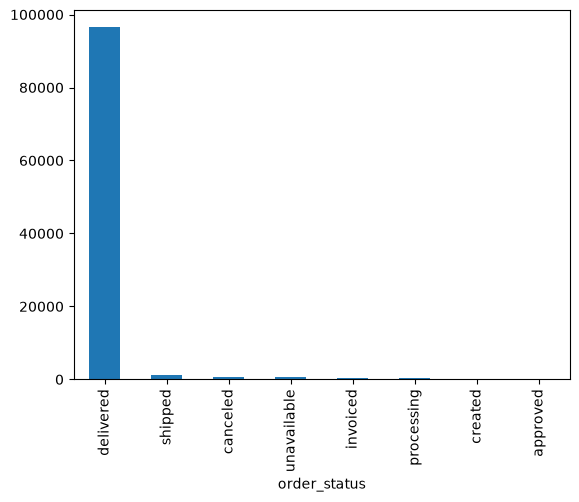

In [37]:
import matplotlib.pyplot as plt
orders["order_status"].value_counts().plot(kind="bar")

In [38]:
orders["order_status"].value_counts(normalize=True)*100

order_status
delivered      97.020344
shipped         1.113223
canceled        0.628513
unavailable     0.612423
invoiced        0.315765
processing      0.302692
created         0.005028
approved        0.002011
Name: proportion, dtype: float64

In [39]:
monthly_orders = (
    orders
    .set_index("order_purchase_timestamp")
    .resample("ME")
    .size()
)

monthly_orders

order_purchase_timestamp
2016-09-30       4
2016-10-31     324
2016-11-30       0
2016-12-31       1
2017-01-31     800
2017-02-28    1780
2017-03-31    2682
2017-04-30    2404
2017-05-31    3700
2017-06-30    3245
2017-07-31    4026
2017-08-31    4331
2017-09-30    4285
2017-10-31    4631
2017-11-30    7544
2017-12-31    5673
2018-01-31    7269
2018-02-28    6728
2018-03-31    7211
2018-04-30    6939
2018-05-31    6873
2018-06-30    6167
2018-07-31    6292
2018-08-31    6512
2018-09-30      16
2018-10-31       4
Freq: ME, dtype: int64

<Axes: xlabel='order_purchase_timestamp'>

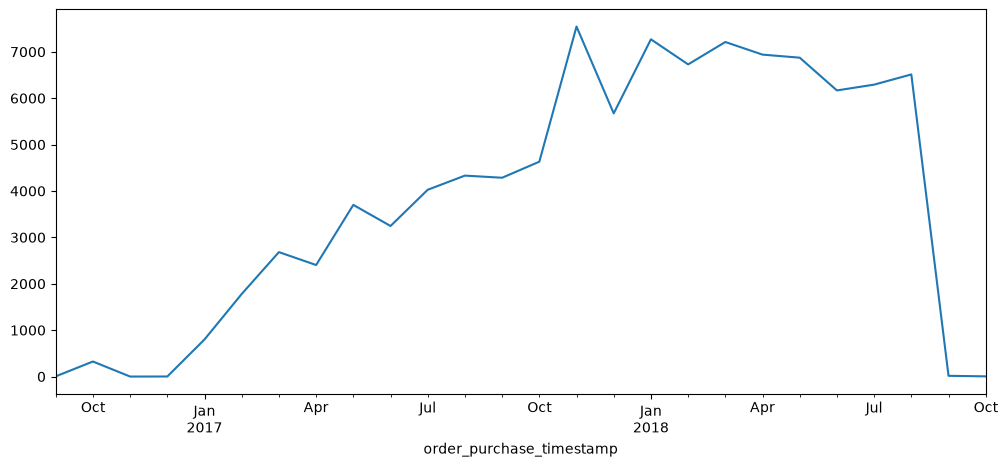

In [40]:
monthly_orders.plot(kind="line", figsize=(12, 5))

In [41]:
payments["payment_value"].describe()

count    103886.000000
mean        154.100380
std         217.494064
min           0.000000
25%          56.790000
50%         100.000000
75%         171.837500
max       13664.080000
Name: payment_value, dtype: float64

In [42]:
order_payments = payments.groupby("order_id")["payment_value"].sum()

total_payment = order_payments.sum()
number_of_orders = order_payments.shape[0]
aov = order_payments.mean()

print("Total payment:", total_payment)
print("Orders with payments:", number_of_orders)
print("AOV:", aov)

Total payment: 16008872.12
Orders with payments: 99440
AOV: 160.9902666934835


In [43]:
monthly_revenue = (
    orders[["order_id", "order_purchase_timestamp"]]
    .merge(order_payments.rename("payment_value"), on="order_id")
)

monthly_revenue["month"] = (
    monthly_revenue["order_purchase_timestamp"]
    .dt.to_period("M")
)

monthly_revenue = (
    monthly_revenue
    .groupby("month")["payment_value"]
    .sum()
)

monthly_revenue

month
2016-09        252.24
2016-10      59090.48
2016-12         19.62
2017-01     138488.04
2017-02     291908.01
2017-03     449863.60
2017-04     417788.03
2017-05     592918.82
2017-06     511276.38
2017-07     592382.92
2017-08     674396.32
2017-09     727762.45
2017-10     779677.88
2017-11    1194882.80
2017-12     878401.48
2018-01    1115004.18
2018-02     992463.34
2018-03    1159652.12
2018-04    1160785.48
2018-05    1153982.15
2018-06    1023880.50
2018-07    1066540.75
2018-08    1022425.32
2018-09       4439.54
2018-10        589.67
Freq: M, Name: payment_value, dtype: float64

In [44]:
monthly_orders = (
    orders["order_purchase_timestamp"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

monthly_aov = monthly_revenue / monthly_orders

print("The Monthly AOV is:")
print(monthly_aov)

The Monthly AOV is:
month
2016-09     63.060000
2016-10    182.378025
2016-12     19.620000
2017-01    173.110050
2017-02    163.993264
2017-03    167.734377
2017-04    173.788698
2017-05    160.248330
2017-06    157.558206
2017-07    147.139324
2017-08    155.713766
2017-09    169.839545
2017-10    168.360587
2017-11    158.388494
2017-12    154.838971
2018-01    153.391688
2018-02    147.512387
2018-03    160.817102
2018-04    167.284260
2018-05    167.900793
2018-06    166.025701
2018-07    169.507430
2018-08    157.006345
2018-09    277.471250
2018-10    147.417500
Freq: M, dtype: float64


In [45]:
id="k3m8qp"
products["product_category_name"].nunique()

73

In [46]:
products["product_category_name"].isin(
    category_translation["product_category_name"]
).mean() * 100

np.float64(98.1093138296258)

In [47]:
# ==========================================
# PRODUCT / CATEGORY EDA
# ==========================================

# 1. Number of unique product categories
print("Unique product categories:", products["product_category_name"].nunique())


# 2. Check translation coverage
translation_coverage = (
    products["product_category_name"]
    .isin(category_translation["product_category_name"])
    .mean() * 100
)

print("\nTranslation coverage:", translation_coverage)


# 3. Find categories without English translation
untranslated_categories = products.loc[
    ~products["product_category_name"].isin(
        category_translation["product_category_name"]
    ),
    "product_category_name"
].dropna().unique()

print("\nUntranslated categories:")
print(untranslated_categories)


# 4. Merge order items with product categories
category_sales = (
    order_items[
        ["order_id", "product_id", "price", "freight_value"]
    ]
    .merge(
        products[["product_id", "product_category_name"]],
        on="product_id",
        how="left"
    )
)


# 5. Add English category names
category_sales = category_sales.merge(
    category_translation,
    on="product_category_name",
    how="left"
)


# 6. Use English category where available
category_sales["category"] = (
    category_sales["product_category_name_english"]
    .fillna(category_sales["product_category_name"])
)


# 7. Category-level sales
category_summary = (
    category_sales
    .groupby("category")
    .agg(
        items_sold=("product_id", "count"),
        sales_value=("price", "sum"),
        freight_value=("freight_value", "sum")
    )
    .sort_values("sales_value", ascending=False)
)


# 8. Average product price by category
category_summary["average_item_price"] = (
    category_summary["sales_value"]
    / category_summary["items_sold"]
)


# 9. Percentage contribution to total item sales
category_summary["sales_share_pct"] = (
    category_summary["sales_value"]
    / category_summary["sales_value"].sum()
    * 100
)


# 10. Top 10 categories by sales value
print("\nTOP 10 CATEGORIES BY SALES VALUE")
print(category_summary.head(10))


# 11. Top 10 categories by number of items sold
print("\nTOP 10 CATEGORIES BY ITEMS SOLD")
print(
    category_summary
    .sort_values("items_sold", ascending=False)
    .head(10)
)


# 12. Top 10 categories by average item price
print("\nTOP 10 CATEGORIES BY AVERAGE ITEM PRICE")
print(
    category_summary
    .sort_values("average_item_price", ascending=False)
    .head(10)
)

Unique product categories: 73

Translation coverage: 98.1093138296258

Untranslated categories:
<StringArray>
['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']
Length: 2, dtype: str

TOP 10 CATEGORIES BY SALES VALUE
                       items_sold  sales_value  freight_value  \
category                                                        
health_beauty                9670   1258681.34      182566.73   
watches_gifts                5991   1205005.68      100535.93   
bed_bath_table              11115   1036988.68      204693.04   
sports_leisure               8641    988048.97      168607.51   
computers_accessories        7827    911954.32      147318.08   
furniture_decor              8334    729762.49      172749.30   
cool_stuff                   3796    635290.85       84039.10   
housewares                   6964    632248.66      146149.11   
auto                         4235    592720.11       92664.21   
garden_tools                 4347    485256.46       9896

In [48]:
top_categories_units = (
    category_summary
    .sort_values("items_sold", ascending=False)
    .head(10)
)

print(top_categories_units[["items_sold", "sales_value", "average_item_price"]])

                       items_sold  sales_value  average_item_price
category                                                          
bed_bath_table              11115   1036988.68           93.296327
health_beauty                9670   1258681.34          130.163531
sports_leisure               8641    988048.97          114.344285
furniture_decor              8334    729762.49           87.564494
computers_accessories        7827    911954.32          116.513903
housewares                   6964    632248.66           90.788148
watches_gifts                5991   1205005.68          201.135984
telephony                    4545    323667.53           71.213978
garden_tools                 4347    485256.46          111.630196
auto                         4235    592720.11          139.957523


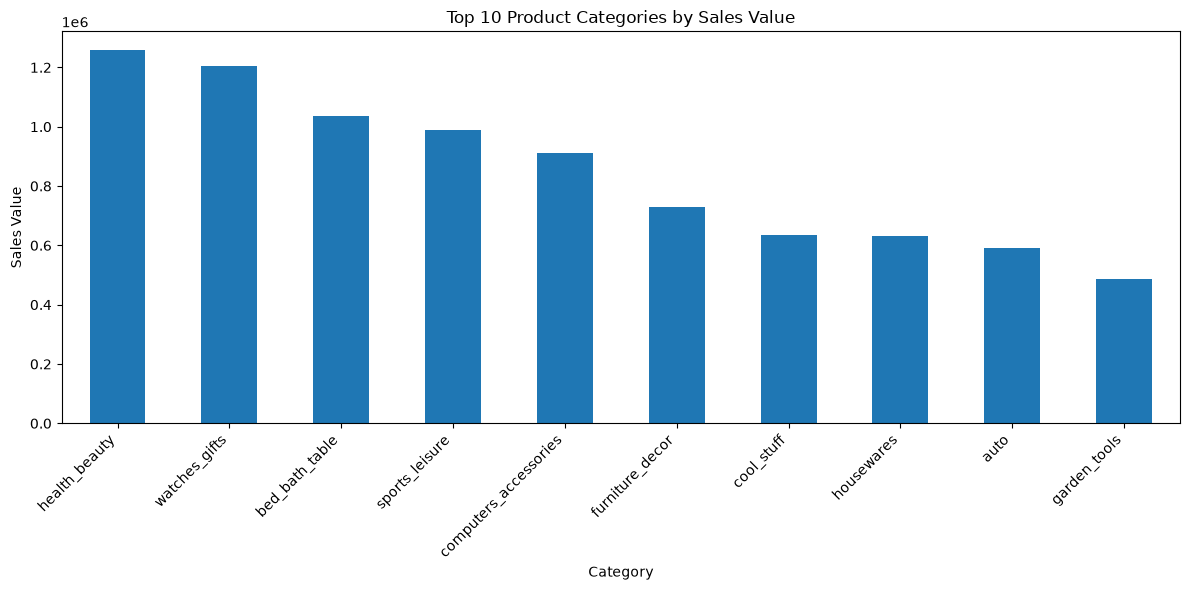

In [49]:
top_10_sales = (
    category_summary
    .sort_values("sales_value", ascending=False)
    .head(10)
)

top_10_sales["sales_value"].plot(
    kind="bar",
    figsize=(12, 6),
    title="Top 10 Product Categories by Sales Value"
)

plt.xlabel("Category")
plt.ylabel("Sales Value")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [50]:
unique_customers = orders["customer_id"].map(
    customers.set_index("customer_id")["customer_unique_id"]
).nunique()

total_orders = orders["order_id"].nunique()

print("Unique customers:", unique_customers)
print("Total orders:", total_orders)
print("Orders per customer:", total_orders / unique_customers)

Unique customers: 96096
Total orders: 99441
Orders per customer: 1.0348089410589412


In [51]:
customer_orders = (
    orders
    .merge(
        customers[["customer_id", "customer_unique_id"]],
        on="customer_id",
        how="left"
    )
    .groupby("customer_unique_id")["order_id"]
    .nunique()
)

one_time_customers = (customer_orders == 1).sum()
repeat_customers = (customer_orders > 1).sum()

print("One-time customers:", one_time_customers)
print("Repeat customers:", repeat_customers)
print("Repeat customer rate:", repeat_customers / len(customer_orders) * 100)

One-time customers: 93099
Repeat customers: 2997
Repeat customer rate: 3.1187562437562435


In [52]:
# ==========================================
# ONE-TIME VS REPEAT CUSTOMER ANALYSIS
# ==========================================

# 1. Connect each order to the actual customer
customer_order_data = (
    orders[["order_id", "customer_id"]]
    .merge(
        customers[["customer_id", "customer_unique_id"]],
        on="customer_id",
        how="left"
    )
)


# 2. Count orders placed by each customer
customer_order_counts = (
    customer_order_data
    .groupby("customer_unique_id")["order_id"]
    .nunique()
    .rename("order_count")
)


# 3. Classify customers
customer_order_counts = customer_order_counts.to_frame()

customer_order_counts["customer_type"] = (
    customer_order_counts["order_count"]
    .apply(lambda x: "Repeat" if x > 1 else "One-time")
)


# 4. Attach customer information to each order
customer_order_data = customer_order_data.merge(
    customer_order_counts,
    on="customer_unique_id",
    how="left"
)


# 5. Attach total payment for each order
customer_value = customer_order_data.merge(
    order_payments.rename("payment_value"),
    on="order_id",
    how="left"
)


# 6. Summarize one-time vs repeat customers
customer_type_summary = (
    customer_value
    .groupby("customer_type")
    .agg(
        customers=("customer_unique_id", "nunique"),
        orders=("order_id", "nunique"),
        total_payment=("payment_value", "sum"),
        average_order_value=("payment_value", "mean")
    )
)


# 7. Calculate average total spending per customer
customer_type_summary["average_customer_spend"] = (
    customer_type_summary["total_payment"]
    / customer_type_summary["customers"]
)


# 8. Display results
print(customer_type_summary)

               customers  orders  total_payment  average_order_value  \
customer_type                                                          
One-time           93099   93099    15064849.41           161.817111   
Repeat              2997    6342      944022.71           148.852524   

               average_customer_spend  
customer_type                          
One-time                   161.815373  
Repeat                     314.989226  


In [53]:
# Customer order frequency

order_frequency = (
    customer_order_counts["order_count"]
    .value_counts()
    .sort_index()
)

print("Customer order frequency:")
print(order_frequency)

print("\nMaximum orders by one customer:")
print(customer_order_counts["order_count"].max())

Customer order frequency:
order_count
1     93099
2      2745
3       203
4        30
5         8
6         6
7         3
9         1
17        1
Name: count, dtype: int64

Maximum orders by one customer:
17


In [54]:
# ============================================================
# FINAL EDA ANALYSIS
# ============================================================

print("=" * 70)
print("1. CUSTOMER ORDER FREQUENCY")
print("=" * 70)

order_frequency = (
    customer_order_counts["order_count"]
    .value_counts()
    .sort_index()
)

print(order_frequency)

print("\nMaximum orders by one customer:")
print(customer_order_counts["order_count"].max())


# ============================================================
# 2. GEOGRAPHIC ANALYSIS
# ============================================================

print("\n" + "=" * 70)
print("2. GEOGRAPHIC ANALYSIS")
print("=" * 70)

customer_geo = (
    orders[["order_id", "customer_id"]]
    .merge(
        customers[
            ["customer_id", "customer_unique_id", "customer_state"]
        ],
        on="customer_id",
        how="left"
    )
)

state_summary = (
    customer_geo
    .groupby("customer_state")
    .agg(
        orders=("order_id", "nunique"),
        customers=("customer_unique_id", "nunique")
    )
    .sort_values("orders", ascending=False)
)

print("\nTop 10 states by orders:")
print(state_summary.head(10))


# ============================================================
# 3. DELIVERY PERFORMANCE
# ============================================================

print("\n" + "=" * 70)
print("3. DELIVERY PERFORMANCE")
print("=" * 70)

delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

print("\nDelivered orders:", len(delivered_orders))

print("\nDelivery days summary:")
print(
    delivered_orders["delivery_days"].describe()
)

delivery_geo = (
    delivered_orders[
        ["order_id", "customer_id", "delivery_days"]
    ]
    .merge(
        customers[
            ["customer_id", "customer_state"]
        ],
        on="customer_id",
        how="left"
    )
)

state_delivery = (
    delivery_geo
    .groupby("customer_state")
    .agg(
        orders=("order_id", "nunique"),
        average_delivery_days=("delivery_days", "mean"),
        median_delivery_days=("delivery_days", "median")
    )
    .sort_values("average_delivery_days", ascending=False)
)

print("\nTop 10 states by average delivery time:")
print(state_delivery.head(10))

print("\nTop 10 states by fastest average delivery:")
print(
    state_delivery
    .sort_values("average_delivery_days")
    .head(10)
)


# ============================================================
# 4. REVIEWS / CUSTOMER SATISFACTION
# ============================================================

print("\n" + "=" * 70)
print("4. REVIEWS / CUSTOMER SATISFACTION")
print("=" * 70)

print("\nReview score distribution:")
print(
    reviews["review_score"]
    .value_counts()
    .sort_index()
)

print("\nAverage review score:")
print(
    reviews["review_score"].mean()
)

review_delivery = (
    reviews[
        ["order_id", "review_score"]
    ]
    .merge(
        orders[
            ["order_id", "delivery_days"]
        ],
        on="order_id",
        how="left"
    )
)

review_delivery_summary = (
    review_delivery
    .groupby("review_score")
    .agg(
        reviews=("order_id", "nunique"),
        average_delivery_days=("delivery_days", "mean")
    )
)

print("\nReview score vs average delivery time:")
print(review_delivery_summary)


# ============================================================
# 5. BUSINESS METRIC RELATIONSHIPS / CORRELATION
# ============================================================

print("\n" + "=" * 70)
print("5. BUSINESS METRIC RELATIONSHIPS")
print("=" * 70)

order_metrics = (
    order_payments.rename("payment_value")
    .to_frame()
    .reset_index()
    .merge(
        orders[
            ["order_id", "delivery_days"]
        ],
        on="order_id",
        how="left"
    )
    .merge(
        reviews[
            ["order_id", "review_score"]
        ],
        on="order_id",
        how="left"
    )
)

correlation_matrix = (
    order_metrics[
        [
            "payment_value",
            "delivery_days",
            "review_score"
        ]
    ]
    .corr()
)

print("\nCorrelation matrix:")
print(correlation_matrix)


# ============================================================
# FINAL EDA SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("FINAL EDA SUMMARY")
print("=" * 70)

print("\nORDER STATUS:")
print(orders["order_status"].value_counts())

print("\nCUSTOMERS:")
print("Unique customers:", unique_customers)
print("Total orders:", total_orders)
print(
    "Orders per customer:",
    round(total_orders / unique_customers, 2)
)
print("One-time customers:", one_time_customers)
print("Repeat customers:", repeat_customers)
print(
    "Repeat customer rate:",
    round(
        repeat_customers / unique_customers * 100,
        2
    ),
    "%"
)

print("\nSALES:")
print("Total payment value:", round(total_payment, 2))
print("Average order value:", round(aov, 2))

print("\nDELIVERY:")
print(
    "Average delivery days:",
    round(
        delivered_orders["delivery_days"].mean(),
        2
    )
)
print(
    "Median delivery days:",
    round(
        delivered_orders["delivery_days"].median(),
        2
    )
)

print("\nREVIEWS:")
print(
    "Average review score:",
    round(
        reviews["review_score"].mean(),
        2
    )
)

print("\nTOP 10 PRODUCT CATEGORIES BY SALES:")
print(
    category_summary[
        ["items_sold", "sales_value", "average_item_price"]
    ]
    .head(10)
)

print("\nEDA ANALYSIS COMPLETE.")

1. CUSTOMER ORDER FREQUENCY
order_count
1     93099
2      2745
3       203
4        30
5         8
6         6
7         3
9         1
17        1
Name: count, dtype: int64

Maximum orders by one customer:
17

2. GEOGRAPHIC ANALYSIS

Top 10 states by orders:
                orders  customers
customer_state                   
SP               41746      40302
RJ               12852      12384
MG               11635      11259
RS                5466       5277
PR                5045       4882
SC                3637       3534
BA                3380       3277
DF                2140       2075
ES                2033       1964
GO                2020       1952

3. DELIVERY PERFORMANCE

Delivered orders: 96478

Delivery days summary:
count    96470.000000
mean        12.558217
std          9.546156
min          0.533414
25%          6.766204
50%         10.217477
75%         15.720182
max        209.628611
Name: delivery_days, dtype: float64

Top 10 states by average delivery time:
     

In [55]:
print("=" * 60)
print("GEOGRAPHIC ANALYSIS")
print("=" * 60)
print(state_summary.head(10))

print("\n" + "=" * 60)
print("DELIVERY PERFORMANCE")
print("=" * 60)
print("Delivered orders:", len(delivered_orders))
print(delivered_orders["delivery_days"].describe())

print("\nSlowest states:")
print(state_delivery.head(10))

print("\nFastest states:")
print(
    state_delivery
    .sort_values("average_delivery_days")
    .head(10)
)

print("\n" + "=" * 60)
print("REVIEW ANALYSIS")
print("=" * 60)
print("Review distribution:")
print(reviews["review_score"].value_counts().sort_index())

print("\nAverage review score:")
print(reviews["review_score"].mean())

print("\nReview vs delivery:")
print(review_delivery_summary)

print("\n" + "=" * 60)
print("CORRELATION")
print("=" * 60)
print(correlation_matrix)

GEOGRAPHIC ANALYSIS
                orders  customers
customer_state                   
SP               41746      40302
RJ               12852      12384
MG               11635      11259
RS                5466       5277
PR                5045       4882
SC                3637       3534
BA                3380       3277
DF                2140       2075
ES                2033       1964
GO                2020       1952

DELIVERY PERFORMANCE
Delivered orders: 96478
count    96470.000000
mean        12.558217
std          9.546156
min          0.533414
25%          6.766204
50%         10.217477
75%         15.720182
max        209.628611
Name: delivery_days, dtype: float64

Slowest states:
                orders  average_delivery_days  median_delivery_days
customer_state                                                     
RR                  41              29.387546             25.007303
AP                  67              27.185068             24.347025
AM                 145   